# **Day 90: Coordinate Systems and Map Projections**

This is one of the most important topics in GIS. Many mistakes in GIS happen because of wrong coordinate systems.

## **The Problem: The Earth is Round, Maps are Flat**
Try to flatten an **orange peel** on a table. It will tear or stretch. In the same way, we **cannot** show the round Earth on a flat map without some **distortion** (change in shape, area, distance or direction).

A **map projection** is a mathematical method to turn the round Earth into a flat map.

## **Two Types of Coordinate Reference Systems (CRS)**
| | Geographic CRS | Projected CRS |
|---|---|---|
| Units | **Degrees** (latitude, longitude) | **Metres** (x, y) |
| Surface | Round Earth | Flat map |
| Example | **WGS84** (EPSG:4326), used by GPS | **UTM Zone 45N** (EPSG:32645) |
| Good for | Storing locations | Measuring distance and area |

**EPSG codes** are ID numbers for coordinate systems. GIS software uses them everywhere.

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt

## **Why We Cannot Measure in Degrees**
- One degree of **latitude** is always about **111 km**.
- One degree of **longitude** gets **shorter** as we go away from the equator. It is **111 km x cos(latitude)**. At the poles it becomes 0.

So a "square" of 1° x 1° is not really a square on the ground.

In [2]:
for place, lat in [("Equator", 0), ("Digha", 21.6), ("Kolkata", 22.6), ("Darjeeling", 27.0), ("London", 51.5), ("Oslo", 60.0)]:
    km_per_lon_degree = 111.32 * math.cos(math.radians(lat))
    print(f"{place:<11} latitude {lat:>4}°: 1° of longitude = {km_per_lon_degree:6.1f} km")

Equator     latitude    0°: 1° of longitude =  111.3 km
Digha       latitude 21.6°: 1° of longitude =  103.5 km
Kolkata     latitude 22.6°: 1° of longitude =  102.8 km
Darjeeling  latitude 27.0°: 1° of longitude =   99.2 km
London      latitude 51.5°: 1° of longitude =   69.3 km
Oslo        latitude 60.0°: 1° of longitude =   55.7 km


That is why the area of a polygon calculated in degrees has **no real meaning**. Before measuring distance or area, we must **project** the data into metres.

## **The UTM System**
**UTM** (Universal Transverse Mercator) divides the Earth into **60 vertical zones**, each **6° of longitude** wide. Inside each zone, the distortion is very small, so it is excellent for measuring.

- Zone number = (longitude + 180) / 6, rounded down, + 1
- West Bengal (about 85.8°E to 89.9°E) lies completely inside **zone 45** (84°E to 90°E).
- In the northern half of the Earth, we call it **45N**, with EPSG code **32645**.

In UTM:
- **Easting (x):** metres from the zone's centre line. The centre line is given the value **500,000 m**, so that values are never negative.
- **Northing (y):** metres from the equator.

In [3]:
def utm_zone(lon):
    return int((lon + 180) // 6) + 1

for place, lon in [("Purulia", 86.36), ("Kolkata", 88.36), ("Cooch Behar", 89.45), ("Delhi", 77.21), ("Mumbai", 72.88)]:
    print(f"{place:<12} longitude {lon:>6}° -> UTM zone {utm_zone(lon)}")

Purulia      longitude  86.36° -> UTM zone 45
Kolkata      longitude  88.36° -> UTM zone 45
Cooch Behar  longitude  89.45° -> UTM zone 45
Delhi        longitude  77.21° -> UTM zone 43
Mumbai       longitude  72.88° -> UTM zone 43


## **Converting Latitude-Longitude to UTM**
The formula below is the standard **Transverse Mercator** formula (from the USGS). It looks long, but we **do not need to remember it**. In real work, the **PyProj** library does this in one line (Day 99). Writing it once helps us understand that a projection is just **maths**.

In [4]:
def latlon_to_utm(lat, lon, zone=None):
    """Convert WGS84 latitude/longitude (degrees) to UTM (metres), northern hemisphere."""
    a = 6378137.0                         # Radius of the Earth at the equator (WGS84)
    f = 1 / 298.257223563                 # How flat the Earth is (WGS84)
    k0 = 0.9996                           # UTM scale factor
    e2 = f * (2 - f)
    ep2 = e2 / (1 - e2)
    zone = zone or utm_zone(lon)
    lon0 = math.radians((zone - 1) * 6 - 180 + 3)          # Centre line of the zone
    phi, lam = math.radians(lat), math.radians(lon)

    N = a / math.sqrt(1 - e2 * math.sin(phi) ** 2)
    T = math.tan(phi) ** 2
    C = ep2 * math.cos(phi) ** 2
    A = math.cos(phi) * (lam - lon0)
    e4, e6 = e2 * e2, e2 ** 3
    M = a * ((1 - e2 / 4 - 3 * e4 / 64 - 5 * e6 / 256) * phi
             - (3 * e2 / 8 + 3 * e4 / 32 + 45 * e6 / 1024) * math.sin(2 * phi)
             + (15 * e4 / 256 + 45 * e6 / 1024) * math.sin(4 * phi)
             - (35 * e6 / 3072) * math.sin(6 * phi))

    easting = k0 * N * (A + (1 - T + C) * A ** 3 / 6 + (5 - 18 * T + T * T + 72 * C - 58 * ep2) * A ** 5 / 120) + 500000
    northing = k0 * (M + N * math.tan(phi) * (A * A / 2 + (5 - T + 9 * C + 4 * C * C) * A ** 4 / 24
                                             + (61 - 58 * T + T * T + 600 * C - 330 * ep2) * A ** 6 / 720))
    return zone, round(easting, 2), round(northing, 2)

places = {"Kolkata": (22.5726, 88.3639), "Howrah Bridge": (22.5851, 88.3468), "Midnapore": (22.4257, 87.3199),
          "Siliguri": (26.7271, 88.3953), "Purulia": (23.3321, 86.3652)}
utm = {}
for name, (lat, lon) in places.items():
    zone, e, n = latlon_to_utm(lat, lon, zone=45)
    utm[name] = (e, n)
    print(f"{name:<14} lat {lat:<8} lon {lon:<8} -> Zone {zone}N  E {e:>11,.1f} m  N {n:>13,.1f} m")

Kolkata        lat 22.5726  lon 88.3639  -> Zone 45N  E   640,220.1 m  N   2,496,848.7 m
Howrah Bridge  lat 22.5851  lon 88.3468  -> Zone 45N  E   638,449.4 m  N   2,498,216.7 m
Midnapore      lat 22.4257  lon 87.3199  -> Zone 45N  E   532,921.0 m  N   2,479,982.3 m
Siliguri       lat 26.7271  lon 88.3953  -> Zone 45N  E   638,775.8 m  N   2,956,969.7 m
Purulia        lat 23.3321  lon 86.3652  -> Zone 45N  E   435,104.0 m  N   2,580,426.3 m


## **Checking the Result**
In UTM, the distance between two points is just the simple **Pythagoras** formula, because the units are metres on a flat map. Let us compare it with the **Haversine** formula (Day 31), which works on the round Earth.

In [5]:
def haversine_m(p1, p2):
    lat1, lon1 = map(math.radians, p1)
    lat2, lon2 = map(math.radians, p2)
    h = math.sin((lat2 - lat1) / 2) ** 2 + math.cos(lat1) * math.cos(lat2) * math.sin((lon2 - lon1) / 2) ** 2
    return 2 * 6371008.8 * math.asin(math.sqrt(h))

for a, b in [("Kolkata", "Howrah Bridge"), ("Kolkata", "Midnapore"), ("Kolkata", "Siliguri")]:
    flat = math.dist(utm[a], utm[b])
    round_earth = haversine_m(places[a], places[b])
    diff = (flat - round_earth) / round_earth * 100
    print(f"{a} -> {b:<14} UTM: {flat / 1000:8.2f} km   Haversine: {round_earth / 1000:8.2f} km   difference {diff:+.2f}%")

Kolkata -> Howrah Bridge  UTM:     2.24 km   Haversine:     2.24 km   difference -0.08%
Kolkata -> Midnapore      UTM:   108.62 km   Haversine:   108.49 km   difference +0.12%
Kolkata -> Siliguri       UTM:   460.12 km   Haversine:   461.97 km   difference -0.40%


The two methods agree within about **half a percent**. The small difference comes from the UTM scale factor and the Earth not being a perfect sphere, and it grows for longer distances (Kolkata to Siliguri is 460 km). For distances inside one district, UTM is very accurate. This shows our projection formula is working.

## **Web Mercator (EPSG:3857): The Projection of Google Maps**
Google Maps, OpenStreetMap and most web maps use **Web Mercator**. It keeps **shapes** correct locally, but it makes areas far from the equator look **much bigger** than they really are.

The stretching factor is **1 / cos(latitude)** in each direction, so the **area** is stretched by **1 / cos²(latitude)**.

In [6]:
def web_mercator(lat, lon):
    R = 6378137.0
    x = R * math.radians(lon)
    y = R * math.log(math.tan(math.pi / 4 + math.radians(lat) / 2))
    return x, y

print("Kolkata in Web Mercator:", [round(v) for v in web_mercator(22.5726, 88.3639)])
print()
for place, lat in [("Kolkata", 22.6), ("Darjeeling", 27.0), ("London", 51.5), ("Greenland (middle)", 72.0)]:
    area_stretch = 1 / math.cos(math.radians(lat)) ** 2
    print(f"{place:<19} areas look {area_stretch:5.2f} times bigger than they are")

Kolkata in Web Mercator: [9836624, 2580413]

Kolkata             areas look  1.17 times bigger than they are
Darjeeling          areas look  1.26 times bigger than they are
London              areas look  2.58 times bigger than they are
Greenland (middle)  areas look 10.47 times bigger than they are


This is why **Greenland looks as big as Africa** on Google Maps, although Africa is actually about **14 times** bigger. For measuring area, never use Web Mercator. Use an equal-area projection or UTM.

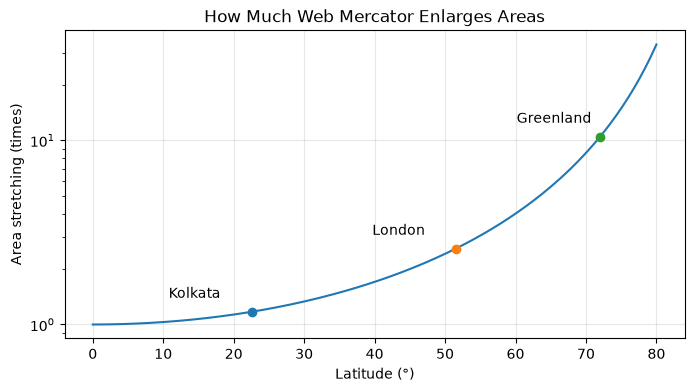

In [7]:
lats = np.linspace(0, 80, 200)
plt.figure(figsize=(8, 4))
plt.plot(lats, 1 / np.cos(np.radians(lats)) ** 2)
for place, lat in [("Kolkata", 22.6), ("London", 51.5), ("Greenland", 72)]:
    plt.scatter(lat, 1 / math.cos(math.radians(lat)) ** 2, zorder=3)
    plt.annotate(place, (lat, 1 / math.cos(math.radians(lat)) ** 2), xytext=(-60, 10), textcoords="offset points")
plt.yscale("log")
plt.xlabel("Latitude (°)")
plt.ylabel("Area stretching (times)")
plt.title("How Much Web Mercator Enlarges Areas")
plt.grid(alpha=0.3)
plt.show()

## **Example: Area of a Field in Degrees vs in Metres**
A farm field near Kharagpur is given by its four corner coordinates. Let us calculate its area using the **Shoelace formula** (Day 45), first in degrees (wrong), then after projecting to UTM (correct).

In [8]:
field = [(22.3302, 87.3230), (22.3302, 87.3262), (22.3279, 87.3262), (22.3279, 87.3230)]   # (lat, lon)

def shoelace(points):
    s = 0
    for (x1, y1), (x2, y2) in zip(points, points[1:] + points[:1]):
        s += x1 * y2 - x2 * y1
    return abs(s) / 2

area_degrees = shoelace([(lon, lat) for lat, lon in field])
field_utm = [latlon_to_utm(lat, lon, 45)[1:] for lat, lon in field]
area_m2 = shoelace(field_utm)

print(f"Area in 'square degrees': {area_degrees:.8f}  (meaningless on the ground)")
print(f"Area after UTM projection: {area_m2:,.0f} square metre = {area_m2 / 10000:.2f} hectare = {area_m2 / 10000 * 7.47:.1f} bigha (approx)")

Area in 'square degrees': 0.00000736  (meaningless on the ground)
Area after UTM projection: 83,898 square metre = 8.39 hectare = 62.7 bigha (approx)


## **Common CRS Codes to Remember**
| EPSG | Name | Used for |
|---|---|---|
| **4326** | WGS84 (latitude/longitude) | GPS, GeoJSON, storing data |
| **32645** | WGS84 / UTM zone 45N | Measuring in West Bengal |
| **32644** | WGS84 / UTM zone 44N | Measuring in central India |
| **3857** | Web Mercator | Web maps (Google, OSM) |

**Golden rule of GIS:** Before putting two layers together, make sure they use the **same CRS**.

In [9]:
# Quick question
# Which CRS should you use to calculate the area of a lake in Kolkata: EPSG:4326 or EPSG:32645?